# Додаткове завдання до модуля 4: візуалізація даних.
В цьому ДЗ ми будемо багато працювати не тільки з візуалізаціями, а і з функціоналом pandas, адже візуалізація даних - це частина аналізу даних та працює спільно з агрегацією та фільтрацією наших даних. До того ж перед тим, як аналізувати дані, їх треба почистити. Чим ми і займемось.  

0.Імпортуйте бібліотеки matplotlib.pyplot, seaborn та pandas.

In [1]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)

## Набір даних Taxis

Використовуючи метод з бібліотеки `seaborn` `load_dataset` ми завантажимо перший набір даних для аналізу. Завантажимо дані так, бо це зручно + аби ви знали, що є і така можливість знайти собі набір даних для експериментів.  
Набір даних містить поїздки таксі у Нью Йорку у 2019 році. Детальний опис на [сайті](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).  

Які колонки мість набір даних:  
- `pickup` - час початку поїздки  
- `dropoff` - час закінчення поїздки  
- `passengers` - кількість пасажирів у поїздці  
- `distance` - відстань поіздки  
- `fare` - базова плата за поїздку  
- `tip` - розмір чайових  
- `tolls` - плата за платні дороги (за це також платить пасажир)  
- `total` - сумарна плата за поїздку  
- `color` - колір авто, яке здійснювало поїздку  
- `payment` - метод оплати  
- `pickup_zone` - зона, у якій почалась поїздка  
- `dropoff_zone` - зона, у якій закінчилась поїздка  
- `pickup_borough` - район, у якому почалась поїздка  
- `dropoff_borough` - район, у якому закінчилась поїздка  

Назви ознак здбільшого говорять самі за себе. Слово borough перекладається з англійської як "район".

Ми будемо працювати сами з тим шматочком даних, які наявні в seaborn.  
Переглянути всі набори даних з seaborn можна [тут](https://github.com/mwaskom/seaborn-data).

Спершу - завантажуємо дані - просто виконайте клітинку нижче.

In [2]:
df_taxi = sns.load_dataset('taxis')

1.Виведіть
- перші 3 записи з набору даних
- типи даних в наборі даних df_taxi
- розміри набору даних

In [3]:
df_taxi.head(3)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan


In [4]:
df_taxi.dtypes

pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                      object
payment                    object
pickup_zone                object
dropoff_zone               object
pickup_borough             object
dropoff_borough            object
dtype: object

In [5]:
df_taxi.shape

(6433, 14)

Очікуваний результат (можна вивести в окремих клітинках):

![](https://drive.google.com/uc?export=view&id=1rsgJvFEdXwGDTVl3CyyRL2ao8rzR_8P2)

2.Перевіримо, чи є в цьому наборі даних пропущені значення. Для цього можемо вивести кількість пропущених значень в кожній колонці наступним чином (це надзвичайно корисна команда, запамʼятайте її):

In [6]:
df_taxi.isna().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Цікаво, чому дані відсутні? Відповідь на це питання нам дасть розуміння, чи можна такі дані видалити, чи можливо їх треба якось заповнити. Виведіть на екран ті рядки, де колонка, яка має найбільше пропущених значень (або одна з тих, що має максимальну кількість пропущених), має пропущені значення.
Подивіться на результат і напишіть свої думки щодо питань:
- чому на ваш погляд в цих рядках є відстуні дані в кількох колонках? Чому ви так думаєте?
- чому на ваш погляд є рядки з distance==0, а total!=0? Як ви до цього прйишли?
Відповідь просто текстом. Можна використовувати будь-які допоміжні операції над датасетом чи джерела, які допоможуть вам відповісти на ці питання. Якщо щось використовуєте, то це треба зазначити у відповіді.  

Ваша відповідь тут - це 70% виконання цього завдання.

In [7]:
missing_dropoff = df_taxi[df_taxi['dropoff_zone'].isna()]
print(f'Рядків без зони висадки: {len(missing_dropoff)}')
missing_dropoff

Рядків без зони висадки: 45


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
42,2019-03-30 23:59:14,2019-03-30 23:59:17,1,0.00,80.0,20.08,0.00,100.38,yellow,credit card,NaN,NaN,NaN,NaN
622,2019-03-12 19:52:36,2019-03-12 19:52:55,3,0.00,120.0,33.20,12.50,166.00,yellow,credit card,NaN,NaN,NaN,NaN
711,2019-03-21 17:39:50,2019-03-21 18:12:54,2,1.74,17.0,4.26,0.00,25.56,yellow,credit card,Midtown East,NaN,Manhattan,NaN
739,2019-03-14 00:09:17,2019-03-14 00:09:21,1,0.03,2.5,0.00,0.00,3.80,yellow,cash,Upper East Side South,NaN,Manhattan,NaN
970,2019-03-29 00:02:00,2019-03-29 00:02:05,2,0.00,45.0,5.00,0.00,50.30,yellow,credit card,NaN,NaN,NaN,NaN
1108,2019-03-10 09:33:13,2019-03-10 09:52:04,1,13.40,52.0,11.70,5.76,70.26,yellow,credit card,NaN,NaN,NaN,NaN
1112,2019-03-12 19:09:23,2019-03-12 19:20:46,1,0.90,8.5,1.92,0.00,14.72,yellow,credit card,Times Sq/Theatre District,NaN,Manhattan,NaN
1230,2019-03-29 07:52:46,2019-03-29 08:02:40,1,0.90,5.5,1.76,0.00,10.56,yellow,credit card,Yorkville East,NaN,Manhattan,NaN
1690,2019-03-22 06:24:14,2019-03-22 06:24:14,1,0.00,72.0,0.00,0.00,72.00,yellow,NaN,East New York,NaN,Brooklyn,NaN
1787,2019-03-28 06:58:57,2019-03-28 07:18:10,1,6.32,20.5,4.26,0.00,25.56,yellow,credit card,Manhattan Valley,NaN,Manhattan,NaN


In [8]:
print('Зона і район висадки порожні одночасно:',
      (df_taxi['dropoff_zone'].isna() == df_taxi['dropoff_borough'].isna()).all())
print('Зона і район посадки порожні одночасно:',
      (df_taxi['pickup_zone'].isna() == df_taxi['pickup_borough'].isna()).all())
print('Із 45 поїздок без зони висадки не мають і зони посадки:', missing_dropoff['pickup_zone'].isna().sum())

pd.DataFrame({
    'Без зони висадки': [missing_dropoff['fare'].median(), (missing_dropoff['tolls'] > 0).mean(),
                         (missing_dropoff['distance'] == 0).mean(), (missing_dropoff['fare'] >= 52).mean()],
    'Усі поїздки': [df_taxi['fare'].median(), (df_taxi['tolls'] > 0).mean(),
                    (df_taxi['distance'] == 0).mean(), (df_taxi['fare'] >= 52).mean()],
}, index=['Медіанний тариф (fare), $', 'Частка з платними дорогами', 'Частка з distance = 0',
          'Частка з тарифом ≥ 52 $']).round(2)

Зона і район висадки порожні одночасно: True
Зона і район посадки порожні одночасно: True
Із 45 поїздок без зони висадки не мають і зони посадки: 21


,Без зони висадки,Усі поїздки
"Медіанний тариф (fare), $",25.00,9.50
Частка з платними дорогами,0.20,0.05
Частка з distance = 0,0.33,0.01
Частка з тарифом ≥ 52 $,0.36,0.03


In [9]:
zero_distance = df_taxi[(df_taxi['distance'] == 0) & (df_taxi['total'] != 0)]
duration_min = (zero_distance['dropoff'] - zero_distance['pickup']).dt.total_seconds() / 60
print(f'Таких поїздок: {len(zero_distance)}')
print(f'Тривалість менше 1 хвилини: {(duration_min < 1).sum()}')
print(f"Посадка і висадка в одній зоні: {(zero_distance['pickup_zone'] == zero_distance['dropoff_zone']).sum()}")
print(f"Без зони висадки: {zero_distance['dropoff_zone'].isna().sum()}")
print('Найчастіші тарифи (fare):', zero_distance['fare'].value_counts().head(5).to_dict())
print('Найчастіші суми (total):', zero_distance['total'].value_counts().head(3).to_dict())

Таких поїздок: 51
Тривалість менше 1 хвилини: 40
Посадка і висадка в одній зоні: 31
Без зони висадки: 15
Найчастіші тарифи (fare): {2.5: 21, 52.0: 5, 25.0: 3, 3.0: 3, 4.0: 2}
Найчастіші суми (total): {3.3: 14, 4.3: 2, 4.8: 2}


**Відповідь**

**1. Чому в цих рядках порожні кілька колонок.**
- Зона і район завжди порожні разом. Район (`borough`) визначають за зоною (`zone`) з довідника зон таксі. Якщо зону не визначено, району теж немає.
- 21 із 45 поїздок не має зони ні посадки, ні висадки, тобто місце не зафіксоване взагалі.
- Ці поїздки нетипові: медіанний тариф 25 \$ проти 9.5 \$ у всіх, платні дороги — у 20 % проти 5 %, тариф від 52 \$ — у 36 % проти 3 %. Схоже, це поїздки за межі Нью-Йорка (Нью-Джерсі, аеропорт Ньюарк, передмістя). Такі точки не входять до карти зон таксі, а для невідомого місця в довіднику зон TLC є окремі коди. У цьому наборі вони стали пропусками.
- Третина цих поїздок має `distance = 0` при тарифі 45–120 \$. Це схоже на поїздки за домовленою ціною, коли лічильник відстані не працював.

**2. Чому є рядки з `distance == 0`, а `total != 0`.** Таких поїздок 51.
- 40 із них тривали менше хвилини, 31 почалася й закінчилася в одній зоні. Найчастіший тариф — 2.5 \$ (21 поїздка), а сума — 3.30 \$. Це мінімальна плата за посадку (2.50 \$) плюс обовʼязкові збори 0.50 \$ і 0.30 \$. Тобто лічильник увімкнули, але поїздка не відбулася: пасажир передумав або вийшов.
- 5 поїздок мають тариф рівно 52 \$ — це фіксований тариф між аеропортом JFK і Мангеттеном. За фіксованого тарифу відстань може не записуватись.
- Решта — ймовірно, збої GPS або лічильника.

**Як я дійшов висновків:** порахував частки й тривалість поїздок у клітинках вище і порівняв тарифи з тарифами таксі Нью-Йорка 2019 року на сайті NYC TLC (nyc.gov): стартова плата 2.50 \$, збори 0.50 \$ і 0.30 \$, фіксований тариф JFK — Мангеттен 52 \$.

3.Заповнимо пусті значення. Оскільки всі колонки набору даних мають пропущені значення в рядках з типом даних рядок, заповнимо пропущені значення рядком `NA`.
Створіть набір даних `df_taxi_clean`, який містить дані `df_taxi` із заповненими пропущеними значеннями у всіх колонках (де ті значення відсутні) значенням `NA`.

**УВАГА!** Надалі в роботі треба використовувати `df_taxi_clean`, ми ж його і створили для того, аби далі ним користуватись :)

In [10]:
df_taxi_clean = df_taxi.fillna('NA')

Після виконання завдання запустіть наступну клітинку:

In [11]:
df_taxi_clean.isna().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Очікуваний результат виконання коду в попердній клітинці:

![](https://drive.google.com/uc?export=view&id=1G5_k_jmtNFFRdn7Kcw_fEoJyrkTeOGP4)

4.Хочеться подивитись на дані у динаміці. Перетворіть колонку `pickup` набору даних `df_taxi_clean` (нам нема чого працювати з "брудними" даними, якщо ми їх вже почистили, але хай будуть в окремій змінній про всяк випадок) у формат `datetime64[ns]`.
Якщо у Вас при завантаженні набору даних колонка `pickup`- вже в форматі `datetime64[ns]` - можете пропустити це завдання, або спробувати все ж таки написат функцію для трансформації.

Результат перетворення збережіть в тій самій колонці `pickup`.

In [12]:
print('Тип до:', df_taxi_clean['pickup'].dtype)
df_taxi_clean['pickup'] = pd.to_datetime(df_taxi_clean['pickup'])
print('Тип після:', df_taxi_clean['pickup'].dtype)

Тип до: datetime64[ns]


Тип після: datetime64[ns]


Після виконання завдання запустіть наступну клітинку:

In [13]:
df_taxi_clean.pickup.head(3)

0   2019-03-23 20:21:09
1   2019-03-04 16:11:55
2   2019-03-27 17:53:01
Name: pickup, dtype: datetime64[ns]

Очікуваний результат виконання коду в попердній клітинці:

![](https://drive.google.com/uc?export=view&id=106hQKdEhLV3OIeFsP8yvXLo0cKk6Jmqo)

5.У нас колонка pickup зараз мість дані у форматі дата-час. Пропоную прибрати час і зробити аналітику по дням. Для цього виконайте клатинку нижче:

In [14]:
df_taxi_clean['pickup_day'] = df_taxi_clean.pickup.dt.floor('d')

А тепер згрупуйте дані по pickup_day та виведіть графік сумарних платежів по дням. УВАГА! Якщо хочете отримати підписи по осі ОХ як на прикладі, то графік необхідно будувати через `df.plot(...)`. Якщо у Вас будуть інші підписи осі ОХ - це ОК.

Після виведення графіку скажіть, чи бачите щось дивне на ньому? Важливо написати відповідь в цьому завданні словами.

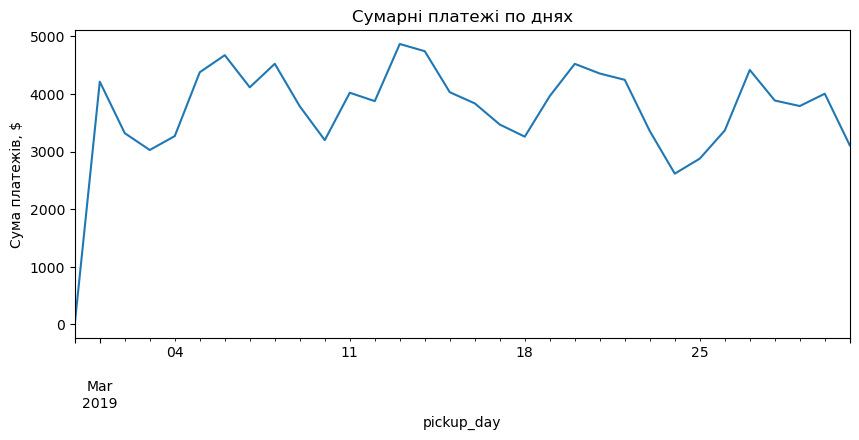

In [15]:
daily_total = df_taxi_clean.groupby('pickup_day')['total'].sum()
daily_total.plot(figsize=(10, 4), title='Сумарні платежі по днях')
plt.ylabel('Сума платежів, $')
plt.show()

**Що дивного на графіку.** На самому початку лінія різко стартує майже з нуля. Це день 2019-02-28: тоді в даних лише одна поїздка, а всі інші дні — березень 2019 року. Цей запис випадково потрапив у вибірку.

Також видно тижневий ритм: суми падають у неділю й понеділок (найменша — 24 березня, близько 2 600 \$) і ростуть до середи–четверга (найбільша — 13 березня, близько 4 900 \$).

Приклад очікуваного графіку:

![](https://drive.google.com/uc?export=view&id=1t8yb_NNO2tfwDFDrBNl0BLJoYB0BsUK_)

6.Виведіть кількість рядків для кожного pickup_day.

In [16]:
df_taxi_clean['pickup_day'].value_counts().sort_index()

pickup_day
2019-02-28      1
2019-03-01    241
2019-03-02    198
2019-03-03    169
2019-03-04    171
2019-03-05    228
2019-03-06    257
2019-03-07    218
2019-03-08    235
2019-03-09    204
2019-03-10    185
2019-03-11    209
2019-03-12    218
2019-03-13    244
2019-03-14    260
2019-03-15    201
2019-03-16    220
2019-03-17    178
2019-03-18    173
2019-03-19    201
2019-03-20    233
2019-03-21    221
2019-03-22    229
2019-03-23    209
2019-03-24    149
2019-03-25    155
2019-03-26    178
2019-03-27    232
2019-03-28    205
2019-03-29    209
2019-03-30    215
2019-03-31    187
Name: count, dtype: int64

Маєте побачити, що для дати 2019-02-28 є тільки один рядок. Це запис, який, схоже, потрапив сюди випадково, видаліть з набору даних df_taxi_clean рядок, що містить pickup_day рівний 2019-02-28. Та знову виведіть графік сумарних платежів по pickup_day.

Лишилось рядків: 6432


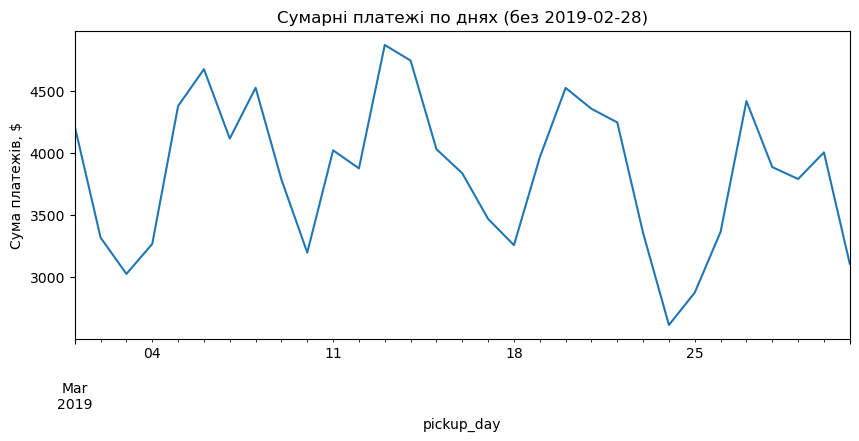

In [17]:
df_taxi_clean = df_taxi_clean[df_taxi_clean['pickup_day'] != '2019-02-28']
print(f'Лишилось рядків: {len(df_taxi_clean)}')

df_taxi_clean.groupby('pickup_day')['total'].sum().plot(figsize=(10, 4),
                                                        title='Сумарні платежі по днях (без 2019-02-28)')
plt.ylabel('Сума платежів, $')
plt.show()

Очікуваний графік:

![](https://drive.google.com/uc?export=view&id=1RfSjsgr5991dlz5bVbfXl8tCnUZhFJ8B)

7.Давайте подивимось на динаміку сумарних платежів по районам. Для цього сформуйте на основі `df_taxi_clean` зводну таблицю, де рядками є `pickup_day`, колонками `pickup_borough`, а значенням - сума платежів. Запишіть зводну таблицю в змінну `borough_pivot`. Наостанок, вилучіть колонку зі значенням `pickup_borough` рівним `NA` - уявімо, що ці дані нас не цікавлять.

In [18]:
borough_pivot = df_taxi_clean.pivot_table(index='pickup_day', columns='pickup_borough',
                                          values='total', aggfunc='sum')
borough_pivot = borough_pivot.drop(columns='NA')
borough_pivot.head()

pickup_borough,Bronx,Brooklyn,Manhattan,Queens
pickup_day,,,,
2019-03-01,123.42,353.05,3169.47,553.29
2019-03-02,NaN,146.56,2716.33,456.13
2019-03-03,80.75,407.06,2100.23,428.73
2019-03-04,92.00,188.73,2026.17,962.18
2019-03-05,98.16,558.40,2981.26,739.56


Далі запустіть наступну клітинку та дайте відповідь на питання, в якому районі найчастіше найбільша сума денних платежів за поїздки на таксі?   
До речі, також рекомендую спробувати запустити команду `borough_pivot.plot()` та зрозуміти, навіщо нам тут частина `fillna(0)`.

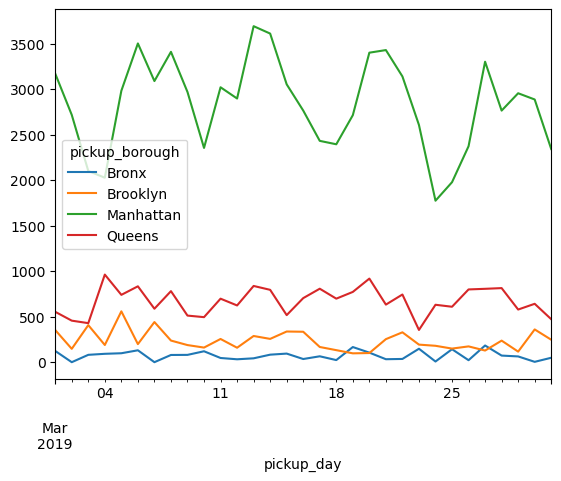

In [19]:
borough_pivot.fillna(0).plot();

Очікуваний графік :

![](https://drive.google.com/uc?export=view&id=1zhLnMdPCg54j2yzU1hRWv6wseSNPT1Oy)

In [20]:
print('Скільки днів район був першим за сумою платежів:')
print(borough_pivot.idxmax(axis=1).value_counts().to_string())
print('\nДнів без жодної поїздки (NaN) у кожному районі:')
print(borough_pivot.isna().sum().to_string())

Скільки днів район був першим за сумою платежів:
Manhattan    31

Днів без жодної поїздки (NaN) у кожному районі:
pickup_borough
Bronx        2
Brooklyn     0
Manhattan    0
Queens       0


**Відповідь.** Найбільша сума денних платежів — щодня в **Мангеттені**: він перший у всі 31 день березня. На нього припадає близько 82 % усіх поїздок вибірки.

**Навіщо `fillna(0)`.** У зведеній таблиці є дні, коли з району не було жодної поїздки (у Бронксі — 2 такі дні). Там стоїть `NaN`, і без `fillna(0)` лінія на графіку переривається. З `fillna(0)` такі дні показані як нуль, і лінія суцільна.

8.Виведіть будь-яким способом гістограми суми денних платежів за поїздки по кожному з районів. Має бути 4 гістограми, на 4ох різних фігурах, або на одній.   

`Підказка:` Найпростіше це буде зробити, використавши `borough_pivot` та побудову графіку через `<назва датафрейму>.<назва графіку>()` - тобто методом датафрейму з пандаса. Але графік можна побудувати також використовуючи цикл. Для тих, хто хоче потренуватись, рекомендую зробити обома способами.

Пограйтесь з кількістю бінів. Яка кількість бінів на ваш погляд тут є вдалою? Чому?

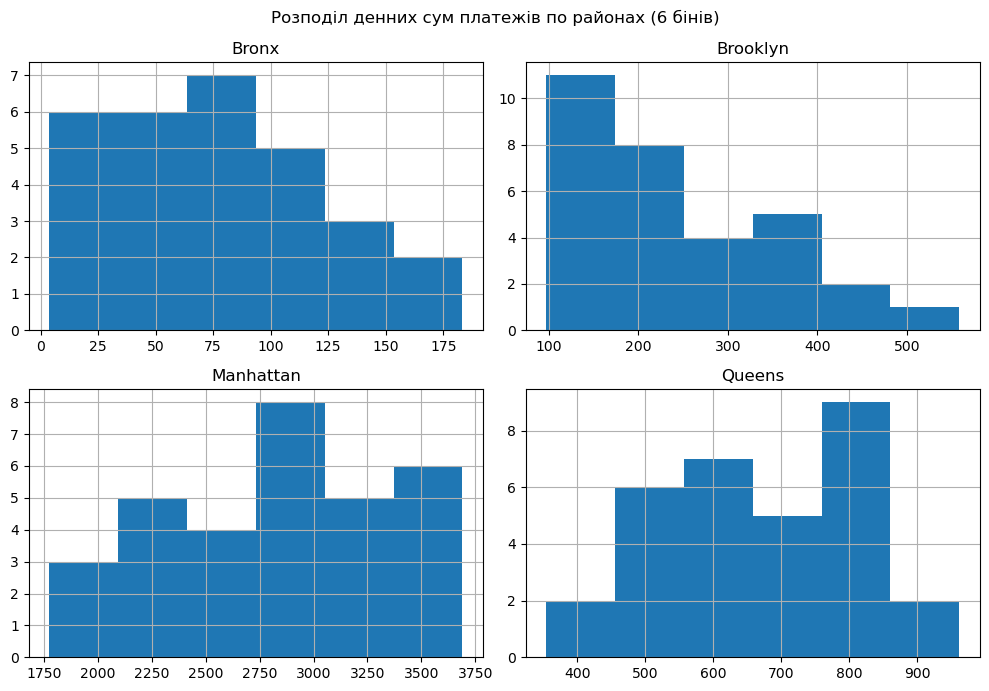

In [21]:
borough_pivot.hist(bins=6, figsize=(10, 7))
plt.suptitle('Розподіл денних сум платежів по районах (6 бінів)')
plt.tight_layout()
plt.show()

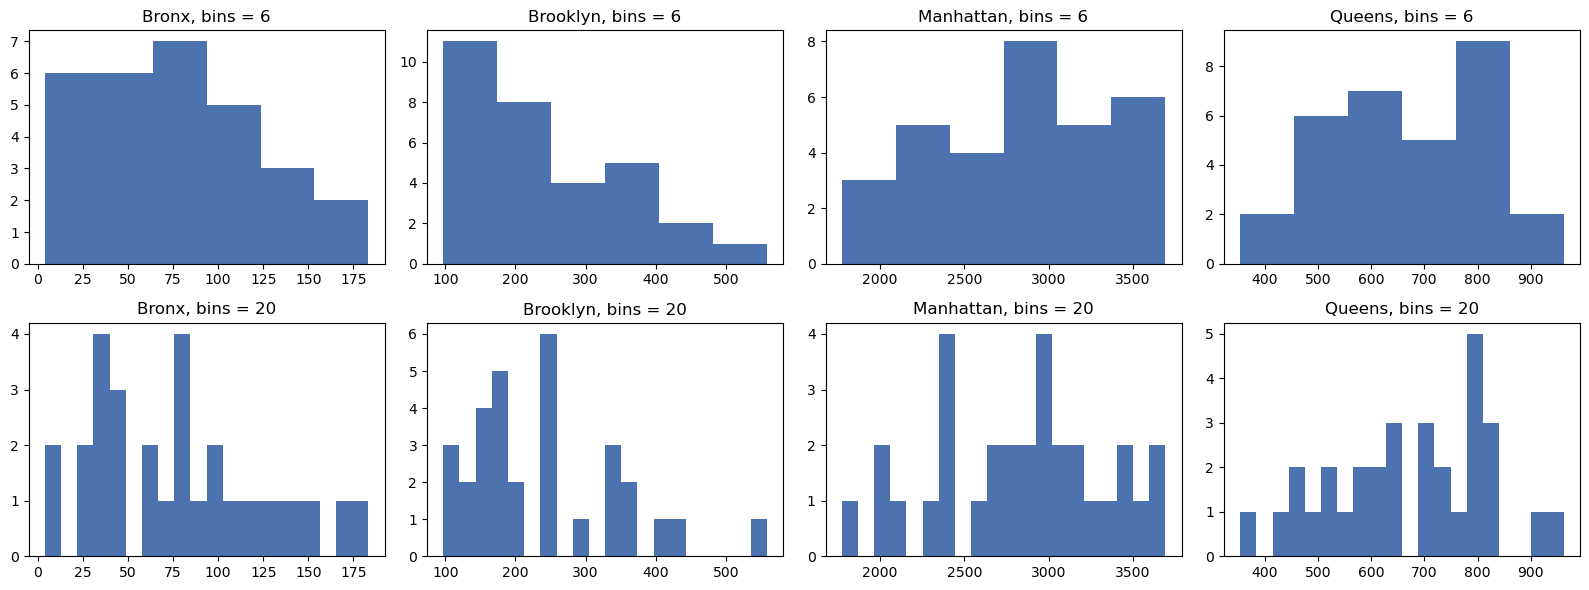

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for col_idx, borough in enumerate(borough_pivot.columns):
    for row_idx, bins in enumerate([6, 20]):
        ax = axes[row_idx, col_idx]
        ax.hist(borough_pivot[borough].dropna(), bins=bins, color='#4C72B0')
        ax.set_title(f'{borough}, bins = {bins}')
plt.tight_layout()
plt.show()

**Скільки бінів обрати.** На кожен район лише 31 значення (днів у березні). При 6 бінах форма розподілу видна чітко: у кожен бін потрапляє кілька днів. Це відповідає правилу Стерджеса: 1 + log₂(31) ≈ 6. При 20 бінах багато бінів порожні або мають 1–2 дні, і гістограма перетворюється на шум. Тому для таких даних найкраще 5–7 бінів.

Приклад одного з правильних виконань завдання:

![](https://drive.google.com/uc?export=view&id=1AfkIgwUAtaDiYoiK6NBOqCHBdUngRz4z)

9.Бачимо, що на окремих гістограмах у нас різні діапазони чеків. Припустимо, нам хочеться порівняти розподіли денних сум платежів по райнам. Давайте для цього виведемо 4 гістограми на одній фігурі. Вони звісно ж мають бути різного кольору і напівпрозорими для комфортного перегляду. Створіть гістограму максимально близьку до тої, що надана в очікуваному результаті.
`Підказка:` ця візуалізація створена з допомогою pandas plotting.

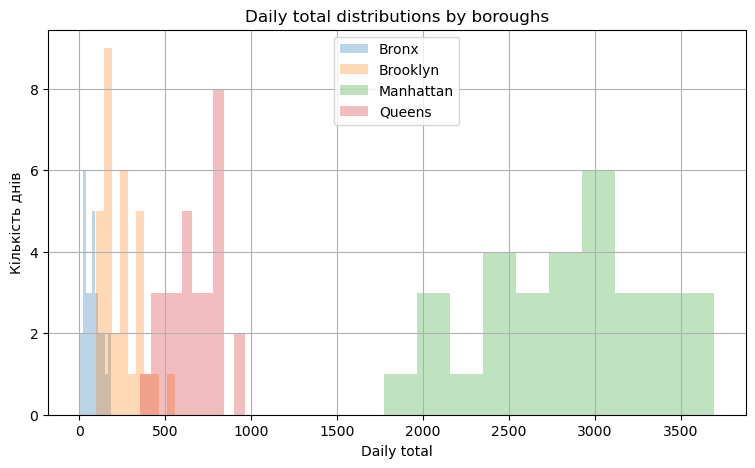

In [23]:
plt.figure(figsize=(9, 5))
for borough in borough_pivot.columns:
    borough_pivot[borough].plot.hist(alpha=0.3, label=borough)
plt.title('Daily total distributions by boroughs')
plt.xlabel('Daily total')
plt.ylabel('Кількість днів')
plt.legend(loc='upper center')
plt.grid(True)
plt.show()

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=1J5PCLfVovNqeGxeeBGFUSS1Kqh6-UnwR)

А ось приклад, як можна було сформувати щось подібне з допомогою функціоналу seaborn. Як на мене візуалізація за замовчанням не є зручною для розуміння.  

`Опціональне завдання`: Пограйтесь з налаштуваннями і пошукайте варіант, за якого візуалізація розподілу суми денних платежів через seaborn є на ваш погляд зручною для аналізу.

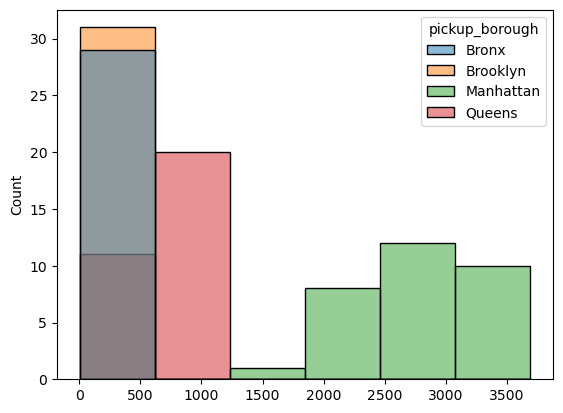

In [24]:
sns.histplot(data=borough_pivot, bins=6);

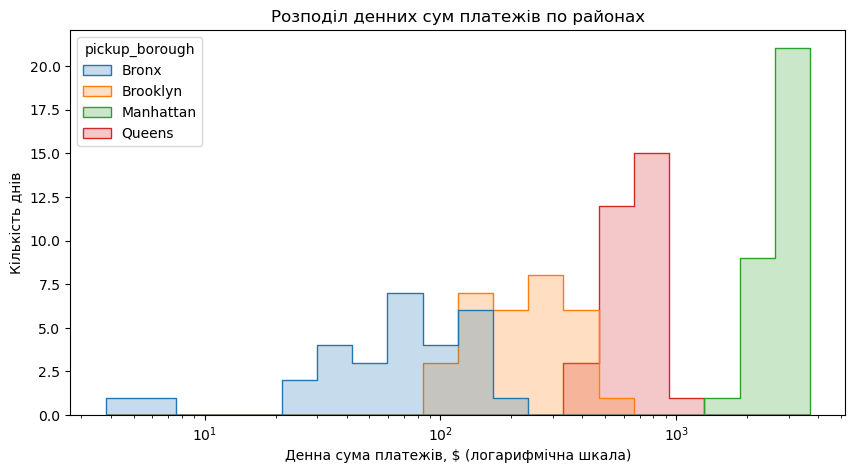

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=borough_pivot, bins=20, log_scale=True, element='step', alpha=0.25, ax=ax)
ax.set_xlabel('Денна сума платежів, $ (логарифмічна шкала)')
ax.set_ylabel('Кількість днів')
ax.set_title('Розподіл денних сум платежів по районах')
plt.show()

**Чому так зручніше.** Денні суми районів відрізняються в десятки разів: Бронкс — сотні доларів, Мангеттен — тисячі. У звичайній шкалі малі розподіли стискаються біля нуля. Логарифмічна шкала розносить їх рівномірно, а контур (`element='step'`) не перекриває інші гістограми.

10.З допомогою seaborn виведіть гістограми суми щомісячних платежів по кольорам автомобілів (колонка `color`). На одній фігурі має бути кількість гістограм рівна кількості різних кольорів автомобілів в наборі даних. Встановіть розмір фігури (10,5) та знайдіть значення dots-per-inch для фігури за якого якість зображення буде хорошою (зображення не буде розмитим).
`Підказки:`
1. побудувати візуалізацію можна в один рядок коду, і ще один рядок - для встановлення розмірів і роздільної здатності фігури.
2. для зміни порядку відображення гістограм кольорів автомобілів (аби менша гістограма була перед, а не за більшою) можна посортувати датафрейм за полем кольору так, аби отримати той порядок, який вам потрібен.

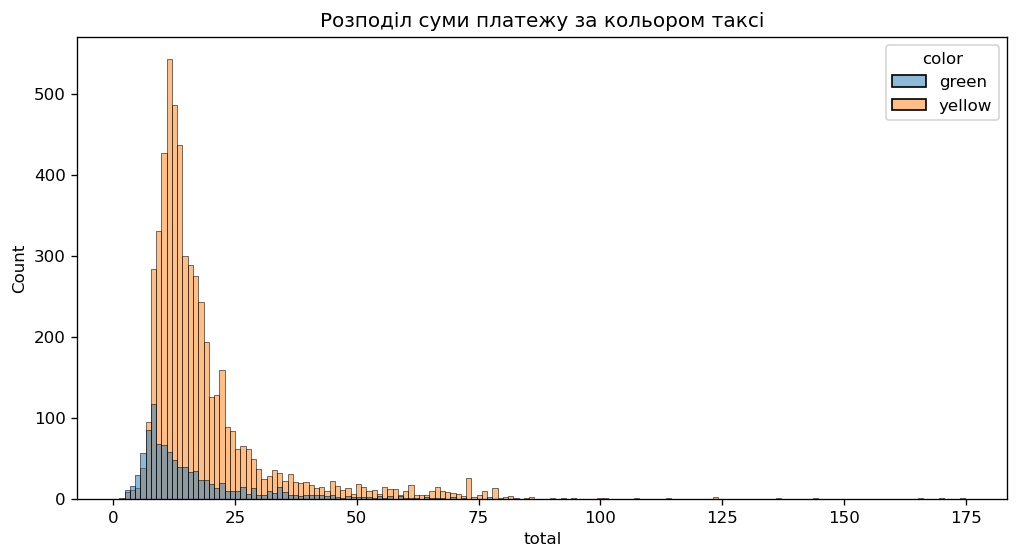

In [26]:
plt.figure(figsize=(10, 5), dpi=120)
sns.histplot(data=df_taxi_clean.sort_values('color'), x='total', hue='color')
plt.title('Розподіл суми платежу за кольором таксі')
plt.show()

Очікуваний результат:

![](https://drive.google.com/uc?export=view&id=17j9hUAo0-65yEuCMHOHUlEW0nRqePOrW)

11.Цікаво, а чи є залежність між дальністю поїздки і розміром чайових? Побудуйте діаграму розсіювання між дальністю поїздки і розміром чайових. Можна побудувати графік будь-яким методом, який вам до вподоби, чи хочеться потренувати.

В очікуваному результаті я надаю графік, який би будувала я. На наведеному прикладі найскладніша частина - це зробити червоною цю лінію тренду (вона побудована з допомогою спеціального типу графіку в seaborn). Аби вказати колір лінії в тому типу графіку треба зазначити в параметрі `line_kws`, що ми хочемо лінію червоного кольору. Але якщо у вас не буде виходити лінія червоного кольору - нехай буде синього - це не критично :)

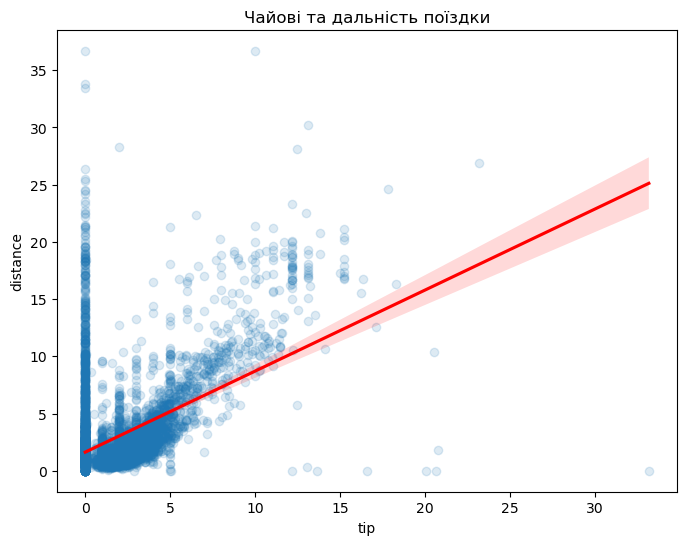

Кореляція tip і distance: 0.45


In [27]:
plt.figure(figsize=(8, 6))
sns.regplot(data=df_taxi_clean, x='tip', y='distance', scatter_kws={'alpha': 0.15}, line_kws={'color': 'red'})
plt.title('Чайові та дальність поїздки')
plt.show()

print('Кореляція tip і distance:', round(df_taxi_clean['tip'].corr(df_taxi_clean['distance']), 2))

Один з можливих результатів (побудовано з seaborn):

![](https://drive.google.com/uc?export=view&id=19PtgLlPTJ1iR_AxcnBDZUw-U3Ulr6Cpy)

12.Дайте відповідь на питання: що означає пряма лінія з точок, паралельна осі, за якою розташована дальність поїздки?

In [28]:
no_tip = df_taxi_clean[df_taxi_clean['tip'] == 0]
print(f'Поїздок з нульовими чайовими: {len(no_tip)} ({len(no_tip) / len(df_taxi_clean):.0%})')
print('Спосіб оплати в поїздках без чайових:', no_tip['payment'].value_counts().to_dict())
print('Частка поїздок без чайових серед оплат готівкою:',
      f"{(df_taxi_clean.loc[df_taxi_clean['payment'] == 'cash', 'tip'] == 0).mean():.0%}")

Поїздок з нульовими чайовими: 2310 (36%)
Спосіб оплати в поїздках без чайових: {'cash': 1811, 'credit card': 455, 'NA': 44}
Частка поїздок без чайових серед оплат готівкою: 100%


**Відповідь.** Вертикальна лінія точок при `tip = 0`, паралельна осі дальності, — це поїздки будь-якої довжини без чайових. Таких 2 310 (36 %). Майже всі вони оплачені готівкою (1 811), а серед оплат готівкою чайові нульові у 100 % поїздок. Причина: у дані потрапляють лише чайові, сплачені карткою, а готівкові чайові не записуються. Тобто нуль тут здебільшого означає «невідомо», а не «пасажир не дав чайових».

13.Побудуйте поденну динаміку чайових по районам, в яких забрали пасажира. Можна побудувати графік будь-яким методом, який вам до вподоби, чи хочеться потренувати. Важливо, щоб на одному графіку було 4 лінії (всі райони, крім `NA`), які відображають динаміку чайових, була легенда і були підписи вісей. В очікуваному результаті я надаю графік, який би будувала я.

Дайте відповіді на питання:
- при початку поїздки в якому районі **найнижчий середній розмір** чайових?
- а в поїздках з якого району **найвищий середній розмір** чайових?
- при проїздках з його району розмір чайових найстабільніший (найменше змінюється з дня у день)?

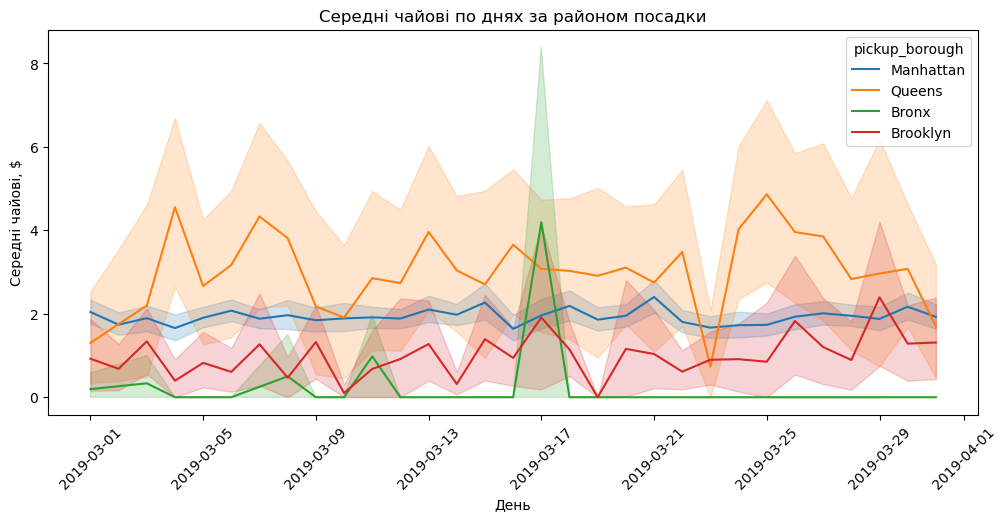

In [29]:
tips_data = df_taxi_clean[df_taxi_clean['pickup_borough'] != 'NA']

plt.figure(figsize=(12, 5))
sns.lineplot(data=tips_data, x='pickup_day', y='tip', hue='pickup_borough')
plt.title('Середні чайові по днях за районом посадки')
plt.xlabel('День')
plt.ylabel('Середні чайові, $')
plt.xticks(rotation=45)
plt.show()

In [30]:
daily_tips = tips_data.groupby(['pickup_day', 'pickup_borough'])['tip'].mean().unstack()
pd.DataFrame({
    'Середні чайові, $': tips_data.groupby('pickup_borough')['tip'].mean(),
    'Розкид денних середніх (std), $': daily_tips.std(),
    'Поїздок': tips_data['pickup_borough'].value_counts(),
}).round(2).sort_values('Середні чайові, $')

,"Середні чайові, $","Розкид денних середніх (std), $",Поїздок
pickup_borough,,,
Bronx,0.15,0.79,99
Brooklyn,0.97,0.51,383
Manhattan,1.94,0.18,5268
Queens,3.04,0.95,656


**Відповіді**

- **Найнижчі середні чайові** — у поїздках із **Бронксу**: 0.15 \$.
- **Найвищі** — із **Квінсу**: 3.04 \$. У Квінсі розташовані аеропорти JFK і LaGuardia, а поїздки звідти довгі й дорогі, тож і чайові більші.
- **Найстабільніші** чайові — у **Мангеттені**: розкид денних середніх лише 0.18 \$ проти 0.5–0.95 \$ в інших районах. Там понад 5 000 поїздок, тож середнє за день майже не коливається.

Один з можливих результатів (побудовано з seaborn):

![](https://drive.google.com/uc?export=view&id=1yoEqYwNwyQmTTrkk_Mz6D-ruAvE-Sx8q)

14.Побудуйте box-plot розміру чайових по району (всі райони, крім `NA`) старту поїздки. Можна побудувати графік будь-яким методом, який вам до вподоби, чи хочеться потренувати.

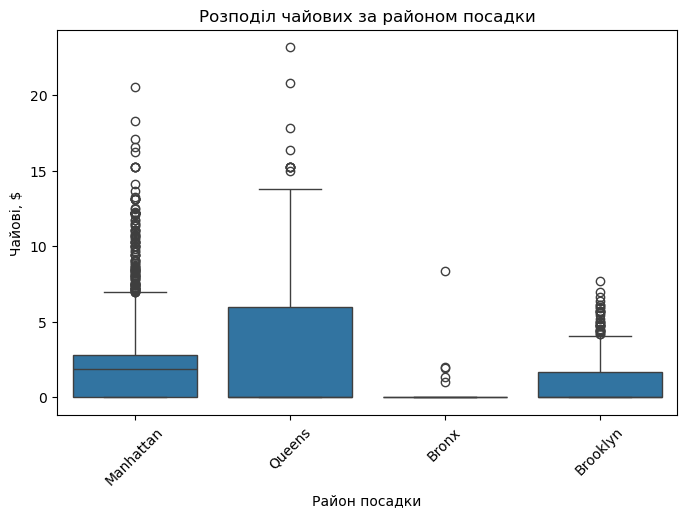

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=tips_data, x='pickup_borough', y='tip')
plt.title('Розподіл чайових за районом посадки')
plt.xlabel('Район посадки')
plt.ylabel('Чайові, $')
plt.xticks(rotation=45)
plt.show()

Один з можливих результатів (побудовано з seaborn):

![](https://drive.google.com/uc?export=view&id=1o6dFRTSj0gLQ_DMWeb7upqvuPNsL0MQc)

15.Творче завдання. Створіть ТРИ інформативних візуалізації, які б допомогли в аналізі цих даних.   

Що вам було б цікаво дізнатись про ці поїздки? Як це можна було б використати при прийнятті рішень бізнесом?
Наприклад, якщо найбільше поїздок в певний час доби, значить, треба стимулювати водіїв працювати в ці години. Якщо найбільше поїздок з певного району - треба тримати там запас авто, які б могли взяти пасажирів і т.д.
Не обмежуйте свою фантазію.

Візуалізації мають бути не тими, на які ми вже побудували вище. Але можна створювати аналогічні, просто з використанням інших полів даних. І описати, що ви бачите з тих візуалізацій.
Без виконання цього завдання ДЗ не приймаєтья. Якщо є питання щодо виконання - пишіть у чат.

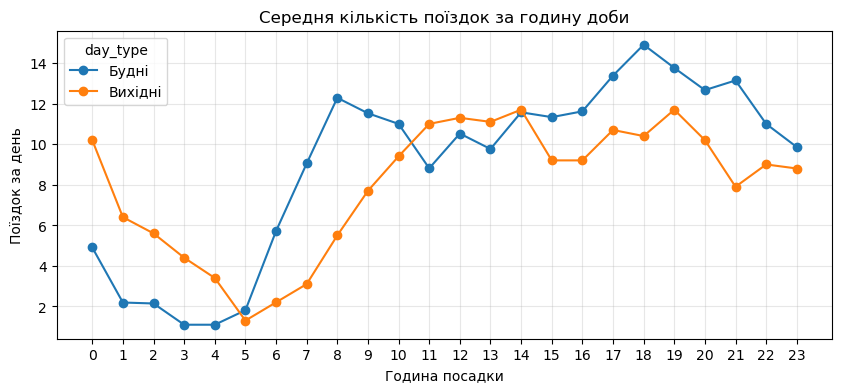

In [32]:
rides = df_taxi_clean.copy()
rides['hour'] = rides['pickup'].dt.hour
rides['day_type'] = rides['pickup'].dt.dayofweek.map(lambda d: 'Вихідні' if d >= 5 else 'Будні')
days_in_type = rides.groupby('day_type')['pickup_day'].nunique()

hourly = rides.groupby(['day_type', 'hour']).size().unstack(0) / days_in_type
hourly.plot(figsize=(10, 4), marker='o')
plt.title('Середня кількість поїздок за годину доби')
plt.xlabel('Година посадки')
plt.ylabel('Поїздок за день')
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

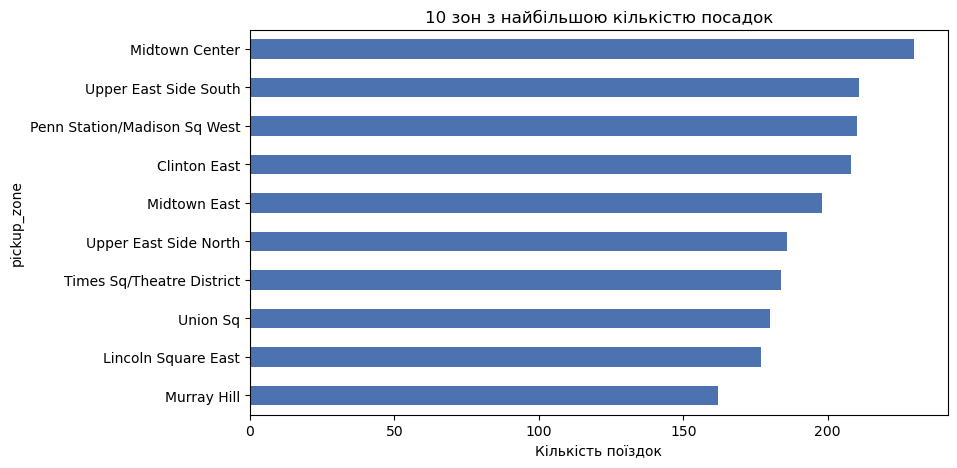

In [33]:
top_zones = rides[rides['pickup_zone'] != 'NA']['pickup_zone'].value_counts().head(10).sort_values()
top_zones.plot(kind='barh', figsize=(9, 5), color='#4C72B0')
plt.title('10 зон з найбільшою кількістю посадок')
plt.xlabel('Кількість поїздок')
plt.show()

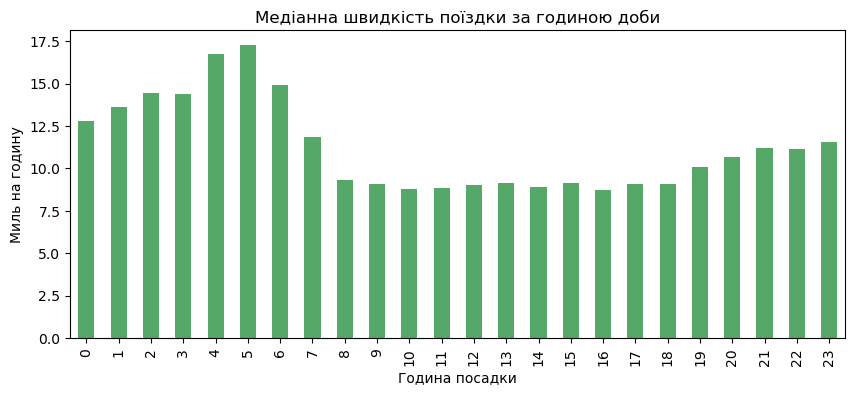

In [34]:
trips = rides[(rides['distance'] > 0)].copy()
trips['duration_h'] = (trips['dropoff'] - trips['pickup']).dt.total_seconds() / 3600
trips = trips[trips['duration_h'] > 1 / 60]
trips['speed_mph'] = trips['distance'] / trips['duration_h']

speed = trips.groupby('hour')['speed_mph'].median()
speed.plot(kind='bar', figsize=(10, 4), color='#55A868')
plt.title('Медіанна швидкість поїздки за годиною доби')
plt.xlabel('Година посадки')
plt.ylabel('Миль на годину')
plt.show()

**Висновки з трьох візуалізацій**

1. **Коли найбільше поїздок.** У будні пік увечері: о 18:00 у середньому 15 поїздок за годину, а о 3:00 ночі — лише одна. У вихідні пік зсувається на день (о 14:00 — близько 12 поїздок), а вночі (з 0:00 до 3:00) поїздок у 2–4 рази більше, ніж у будні. Для бізнесу: стимулювати водіїв працювати у вечірній пік буднів і вночі на вихідних.
2. **Де тримати авто.** Найбільше посадок у центрі Мангеттена: Midtown Center (230), Upper East Side South (211), Penn Station/Madison Sq West (210), Clinton East (208), Midtown East (198). Тут варто тримати резерв вільних машин.
3. **Затори.** Удень (з 8:00 до 18:00) медіанна швидкість лише близько 9 миль на годину, найнижча — о 16:00 (8.7). О 5:00 ранку вона майже вдвічі вища (17.3). Для бізнесу: удень поїздки довші за часом, тож прогноз часу прибуття і тарифи за час мають це враховувати.